# TP 2 — Vectorisation et word embeddings

**Objectifs.** Lire la forme et la sparsité d’une représentation, distinguer one-hot, Bag of Words, TF-IDF et n-grammes, puis interpréter la géométrie d’un embedding. Durée : 2–3 h pour les sections locales.

**Données et licence.** Le TP historique utilise `test/14826` de Reuters-21578 via NLTK. Son usage est soumis aux [conditions de recherche indiquées par NLTK](https://github.com/nltk/nltk_data/blob/gh-pages/DATASET-LICENSES.md). Les sorties sont effacées du dépôt. Installer `python -m pip install -e ".[nlp]"` pour les sections 1–5.

**Modèles préentraînés facultatifs.** Les cellules Word2Vec, GloVe et FastText sont commentées car les téléchargements peuvent atteindre plusieurs centaines de Mo ou davantage. Les sections 1–5 et les visualisations restent exécutables sans ces modèles. Pour une comparaison réelle, vérifier aussi la licence de chaque modèle externe.


## 1. Préparer les phrases

Chaque phrase sert ici de document. Le tokenizer et la normalisation définissent le vocabulaire que les vectorizers verront ensuite. Dans un projet de classification, le vocabulaire s’ajuste sur l’entraînement seulement ; ce TP descriptif porte sur un article isolé.

In [ ]:
"""TP2 - Vectorisation et word embeddings pré-entraînés."""
import html, re, string, unicodedata, time
from collections import Counter
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import reuters, stopwords
from nltk.tokenize import sent_tokenize, word_tokenize

for resource in ['reuters', 'punkt', 'punkt_tab', 'stopwords']:
    nltk.download(resource, quiet=True)

stop_words = set(stopwords.words('english'))
def clean_text(text: str) -> str:
    text = html.unescape(text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    return re.sub(r' {2,}', ' ', re.sub(r'[\n\t\r]+', ' ', text)).strip()

SUFFIXES_CONTRACTION = {"'s", "'re", "'ve", "'ll", "'d", "'m"}
IRREGULAR = {'ca': 'can', 'wo': 'will', 'sha': 'shall'}
def fix_contractions(tokens):
    result=[]; i=0
    while i < len(tokens):
        following=tokens[i+1].lower() if i+1<len(tokens) else ''
        if following == "n't":
            result.extend([IRREGULAR.get(tokens[i].lower(),tokens[i]),'not']); i+=2
        elif tokens[i].lower() in SUFFIXES_CONTRACTION: i+=1
        else: result.append(tokens[i]); i+=1
    return result

def normalize(tokens):
    tokens=fix_contractions(tokens)
    tokens=[unicodedata.normalize('NFKD',t.lower()).encode('ascii','ignore').decode() for t in tokens]
    punctuation=set(string.punctuation)|{'$','%','&'}
    return [t for t in tokens if t not in punctuation and t not in stop_words and t.isalpha() and len(t)>=2]

texte_art=reuters.raw(fileids=['test/14826'])
def phrases_normalisees(texte):
    phrases=[normalize(word_tokenize(s)) for s in sent_tokenize(clean_text(texte))]
    return [' '.join(p) for p in phrases if p]
def phrases_tokenisees(texte):
    phrases=[]
    for s in sent_tokenize(clean_text(texte)):
        toks=[t for t in word_tokenize(s) if t.isalpha()]
        if toks: phrases.append(toks)
    return phrases

textes_art=phrases_normalisees(texte_art)
phrases_art=phrases_tokenisees(texte_art)
print('Phrases:',len(textes_art),'| premier document normalisé:',textes_art[0])

## 2. Inspecter le texte nettoyé

La comparaison de deux formes d’une phrase révèle les mots-outils et la casse supprimés. Cette décision affecte la dimension et les similarités calculées plus loin.

In [ ]:
print('\nSECTION 1 - Préparer l’article')
print('Normalisé [1]:',textes_art[1])
print('Tokenisé [1]:',' '.join(phrases_art[1]))

## 3. One-hot : identités orthogonales

Pour un vocabulaire de taille `V`, chaque mot a un vecteur de forme `(V,)` avec un seul `1`. Deux mots distincts ont un produit scalaire nul, même s’ils sont proches dans le langage. Le tableau de tous les tokens a donc beaucoup de zéros.

In [ ]:
print('\nSECTION 2 - One-hot')
from sklearn.metrics.pairwise import cosine_similarity
tokens_art=[t for doc in textes_art for t in doc.split()]
vocab_art=sorted(set(tokens_art)); index={mot:i for i,mot in enumerate(vocab_art)}
def one_hot(mot,index):
    v=np.zeros(len(index),dtype=np.int8); v[index[mot]]=1; return v
M=np.stack([one_hot(t,index) for t in tokens_art])
print('Matrice one-hot:',M.shape,'| taux de remplissage:',round(float(M.mean()),6))
print('cos(trade, tariffs)=',cosine_similarity([one_hot('trade',index)],[one_hot('tariffs',index)])[0,0])
print('cos(trade, japan)=',cosine_similarity([one_hot('trade',index)],[one_hot('japan',index)])[0,0])
try: one_hot('wheat',index)
except KeyError as exc: print('wheat absent: KeyError',exc)

## 4. Bag of Words : compter sans ordre

La matrice `X_bow` a une ligne par phrase et une colonne par terme appris. Une cellule contient le nombre d’occurrences. L’ordre des mots est perdu : deux permutations ont le même vecteur. Les termes absents du vocabulaire appris sont ignorés par `transform`.

In [ ]:
print('\nSECTION 3 - Bag of Words')
from sklearn.feature_extraction.text import CountVectorizer
param=dict(tokenizer=str.split,token_pattern=None,lowercase=False)
cv=CountVectorizer(**param); X_bow=cv.fit_transform(textes_art); noms=cv.get_feature_names_out()
print('Dimension:',X_bow.shape,'| densité:',round(X_bow.nnz/np.prod(X_bow.shape),4))
termes=['trade','japan','tariffs','exports','said']
print(pd.DataFrame(X_bow[:6].toarray(),columns=noms)[termes].to_string(index=False))
totaux=np.asarray(X_bow.sum(axis=0)).ravel()
print('Top 8 termes:',list(zip(noms[totaux.argsort()[-8:][::-1]],totaux[totaux.argsort()[-8:][::-1]])))
queries=cv.transform(['japan exports tariffs','tariffs exports japan'])
print('Vecteurs des permutations identiques:',(queries[0]!=queries[1]).nnz==0)
texte_14828=reuters.raw(fileids=['test/14828']); textes_14828=phrases_normalisees(texte_14828)
tok_14828=[t for d in textes_14828 for t in d.split()]
oov_bow=[t for t in tok_14828 if t not in cv.vocabulary_]
print('OOV article 14828:',len(oov_bow),'/',len(tok_14828),'=',round(len(oov_bow)/max(len(tok_14828),1),3),'| occurrences non nulles après transform:',cv.transform(textes_14828).nnz)

## 5. TF-IDF : pondérer la rareté documentaire

TF-IDF atténue les termes présents dans beaucoup de documents et normalise souvent chaque ligne. Dans scikit-learn, `idf(t)=log((1+n)/(1+df(t)))+1` avec lissage par défaut ; la valeur finale dépend aussi du nombre d’occurrences et de la normalisation L2. Le corpus minuscule rend ces poids instables.

In [ ]:
print('\nSECTION 4 - TF-IDF')
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer(**param); X_tfidf=tfidf.fit_transform(textes_art); noms_tfidf=tfidf.get_feature_names_out()
print(pd.DataFrame(X_tfidf[:6].toarray(),columns=noms_tfidf)[termes].round(2).to_string(index=False))
idf=tfidf.idf_; order=idf.argsort()
print('IDF faible:',[(noms_tfidf[i],round(idf[i],2)) for i in order[:4]])
print('IDF élevé:',[(noms_tfidf[i],round(idf[i],2)) for i in order[-3:]])
said_i=tfidf.vocabulary_.get('said'); print('IDF said:',round(idf[said_i],3) if said_i is not None else 'absent')
print('Termes avec IDF maximal:',int(np.isclose(idf,idf.max()).sum()))
sims=cosine_similarity(X_tfidf); np.fill_diagonal(sims,0)
i,j=np.unravel_index(sims.argmax(),sims.shape)
print(f'Phrases les plus proches (cos={sims[i,j]:.3f}):\n- {textes_art[i]}\n- {textes_art[j]}')
paires=sims[np.triu_indices_from(sims,1)]
zero=np.argwhere(np.triu(sims==0,1))
print('Part de paires à cosinus nul:',round(float((paires==0).mean()),3))
print('Exemple de paire à cosinus nul:',(textes_art[zero[0,0]],textes_art[zero[0,1]]) if len(zero) else 'aucune')

### Visualisation — poids TF-IDF par phrase

Chaque carré représente le poids d’un terme dans une phrase inventée pour la démonstration. Une colonne très sombre signale un poids nul ou faible ; un poids nul ne prouve pas l’absence de relation sémantique.

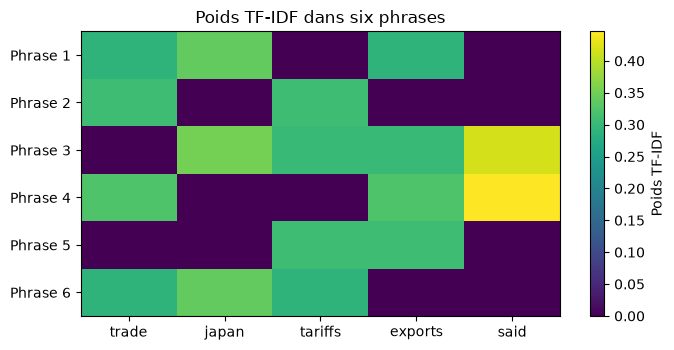

In [ ]:
import matplotlib.pyplot as plt
toy_sentences = [
    "Japan exports cars through global trade",
    "New tariffs change trade costs",
    "Japan said tariffs may affect exports",
    "Trade data said exports increased",
    "Tariffs on exports changed prices",
    "Japan and trade partners discussed tariffs",
]
toy_tfidf = TfidfVectorizer()
toy_matrix = toy_tfidf.fit_transform(toy_sentences)
selected_terms = ["trade", "japan", "tariffs", "exports", "said"]
selected_ids = [toy_tfidf.vocabulary_[term] for term in selected_terms]
weights_by_phrase = toy_matrix[:, selected_ids].toarray()
fig, ax = plt.subplots(figsize=(7, 3.6))
image = ax.imshow(weights_by_phrase, aspect="auto", cmap="viridis", vmin=0)
ax.set_xticks(range(len(selected_terms)), selected_terms)
ax.set_yticks(range(6), [f"Phrase {index + 1}" for index in range(6)])
ax.set_title("Poids TF-IDF dans six phrases")
fig.colorbar(image, ax=ax, label="Poids TF-IDF")
plt.tight_layout()
plt.show()

## 6. N-grammes : garder un peu d’ordre

Un bigramme utilise deux tokens voisins. Il peut distinguer des expressions que Bag of Words confond, mais augmente rapidement la dimension et la rareté. Tester `(1, n)` permet de voir cette croissance.

In [ ]:
print('\nSECTION 5 - N-grammes')
rows=[]
for n in (1,2,3):
    X=TfidfVectorizer(ngram_range=(1,n),**param).fit_transform(textes_art)
    rows.append({'ngram_range':f'(1, {n})','Dimension':X.shape[1],'Valeurs non nulles':X.nnz,'Zéros (%)':round(100*(1-X.nnz/np.prod(X.shape)),2)})
print(pd.DataFrame(rows).to_string(index=False))
tfidf_ng=TfidfVectorizer(ngram_range=(1,2),**param); X_ng=tfidf_ng.fit_transform(textes_art); noms_ng=tfidf_ng.get_feature_names_out()
ligne=X_ng[1].toarray().ravel(); print('Top termes pour phrase [1]:',[(noms_ng[k],round(ligne[k],3)) for k in ligne.argsort()[-6:][::-1]])
bigram_docfreq=Counter(bg for doc in textes_art for bg in set(zip(doc.split(),doc.split()[1:])))
print('Bigrammes présents dans une seule phrase:',sum(freq==1 for freq in bigram_docfreq.values()))
bank_japan=' '.join(normalize(word_tokenize('bank of Japan')))
print('Normalisation de "bank of Japan":',bank_japan,'| bigramme présent dans l’article ?',bank_japan in noms_ng)

## 7. Word2Vec : embeddings de contexte

Un embedding est un vecteur dense appris à partir de contextes. Des voisins proches peuvent être associés par usage, pas seulement synonymes. La cellule facultative de téléchargement reste désactivée ; la figure géométrique suivante montre uniquement des vecteurs **inventés** pour expliquer le cosinus.

In [ ]:
print('\nSECTION 6 - Word2Vec (téléchargement ~1,7 Go au premier lancement)')
print('Cette cellule est volontairement séparée : exécutez-la seulement si le téléchargement et ~0,5 Go de RAM sont acceptables.')
# import gensim.downloader as api
# from gensim.models import KeyedVectors
# chemin = api.load('word2vec-google-news-300', return_path=True)
# debut=time.time(); w2v=KeyedVectors.load_word2vec_format(chemin,binary=True,limit=300000)
# print('Vocabulaire chargé:',len(w2v),'| dimension:',w2v.vector_size,'| secondes:',round(time.time()-debut))
# def top(wv,mot,k=6): return [w for w,_ in wv.most_similar(mot,topn=k)]
# for mot in ['Japan','japan','crude_oil','the','of','and','dlrs']:
#     print(mot,'présent' if mot in w2v else 'absent')
# print(pd.DataFrame([{'Mot':m,'Voisins Word2Vec':', '.join(top(w2v,m,5))} for m in ['oil','Oil','profit','dollar','wheat','tariffs','Japan','japan']]).to_string(index=False))

### Visualisation — intuition du cosinus entre embeddings

Ces points 2D sont **inventés pour la démonstration** et ne proviennent d’aucun modèle entraîné. Le cosinus mesure l’angle entre deux vecteurs depuis l’origine. Dans un espace appris, une proximité doit encore être validée sur des exemples de la tâche.

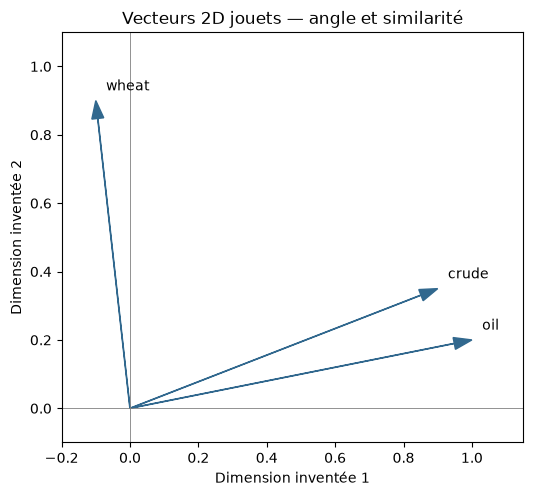

In [ ]:
toy_vectors = {"oil": np.array([1.0, 0.2]), "crude": np.array([0.9, 0.35]), "wheat": np.array([-0.1, 0.9])}
fig, ax = plt.subplots(figsize=(5.5, 5))
for word, vector in toy_vectors.items():
    ax.arrow(0, 0, vector[0], vector[1], head_width=0.035, length_includes_head=True, color="#31688e")
    ax.text(vector[0] + 0.03, vector[1] + 0.03, word)
ax.set(xlim=(-0.2, 1.15), ylim=(-0.1, 1.1), xlabel="Dimension inventée 1", ylabel="Dimension inventée 2", title="Vecteurs 2D jouets — angle et similarité")
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()
for word in ["crude", "wheat"]:
    cosine = float(np.dot(toy_vectors["oil"], toy_vectors[word]) / (np.linalg.norm(toy_vectors["oil"]) * np.linalg.norm(toy_vectors[word])))
    print(f"cosine(oil, {word}) = {cosine:.3f}")

## 8. GloVe : cooccurrences globales

GloVe apprend à partir de statistiques de cooccurrence. Sa comparaison avec Word2Vec demande un vocabulaire et un corpus adaptés. Deux espaces entraînés séparément n’ont pas de coordonnées alignées ; comparer des voisinages, pas les valeurs brutes de leurs axes.

In [ ]:
print('\nSECTION 7 - GloVe (~130 Mo)')
print('À lancer après l’installation de gensim et le chargement Word2Vec.')
# glove=api.load('glove-wiki-gigaword-100')
# vocab_art_token=sorted({t for s in phrases_art for t in s})
# print('Vocabulaire GloVe:',len(glove),'| dimension:',glove.vector_size)
# print('Absents de Word2Vec:',sum(t not in w2v for t in vocab_art_token),'| absents de GloVe:',sum(t.lower() not in glove for t in vocab_art_token))
# print(pd.DataFrame([{'Mot':m,'Word2Vec':', '.join(top(w2v,m,4)),'GloVe':', '.join(top(glove,m.lower(),4))} for m in ['oil','crude','shares','tender','bank']]).to_string(index=False))

## 9. FastText : sous-mots

FastText décompose les mots en fragments de caractères. Cela peut aider pour flexions et fautes proches, sans garantir qu’un mot inconnu reçoit un sens fiable. Le chargement facultatif reste commenté pour que le notebook local s’exécute sans gros téléchargement.

In [ ]:
print('\nSECTION 8 - FastText compressé (~240 Mo)')
print('À lancer seulement si les dépendances et le téléchargement externe sont disponibles.')
# import os, urllib.request, compress_fasttext
# FICHIER='ft_cc.en.300_freqprune_400K_100K_pq_300.bin'
# URL='https://github.com/avidale/compress-fasttext/releases/download/gensim-4-draft/'+FICHIER
# if not os.path.exists(FICHIER): urllib.request.urlretrieve(URL,FICHIER)
# debut=time.time(); fasttext=compress_fasttext.models.CompressedFastTextKeyedVectors.load(FICHIER)
# print('Vocabulaire:',len(fasttext),'| dimension:',fasttext.vector_size,'| secondes:',round(time.time()-debut))
# def voisins_ft(mot,k=3): return [w for w in top(fasttext,mot,30) if len(w)<=20][:k]
# for mot in ['tarifs','dolars','oilprices']:
#     print(mot,'FastText:',mot in fasttext.key_to_index,'Word2Vec:',mot in w2v,'GloVe:',mot in glove,voisins_ft(mot))
# print('cos(tarifs, tariffs)=',round(float(fasttext.similarity('tarifs','tariffs')),2))
# print('cos(tarifs, wheat)=',round(float(fasttext.similarity('tarifs','wheat')),2))
# print("zzqxqz in fasttext:",'zzqxqz' in fasttext,'| dans le vocabulaire:', 'zzqxqz' in fasttext.key_to_index)
# for mot in ['heavily','exports']:
#     print(mot,'Word2Vec:',top(w2v,mot,5),'| FastText:',voisins_ft(mot,5))

## 10. Choisir une représentation

Comparez couverture du vocabulaire, taille, coût de calcul et qualité sur une tâche tenue à l’écart. La meilleure représentation dépend du domaine et de l’erreur que vous voulez réduire.

In [ ]:
print('\nSECTION 9 - Comparaison des modèles')
print('Les valeurs numériques dépendent des modèles chargés; la cellule suivante est décommentable après les sections 6 à 8.')
# print(pd.DataFrame([{'Mot':m,'Word2Vec':', '.join(top(w2v,m,3)),'GloVe':', '.join(top(glove,m.lower(),3)),'FastText':', '.join(voisins_ft(m))} for m in ['oil','bank','tariffs','profit']]).to_string(index=False))
# for a,b in [('oil','crude'),('oil','wheat')]:
#     print(f'{a}-{b}: Word2Vec {w2v.similarity(a,b):.2f} | GloVe {glove.similarity(a,b):.2f} | FastText {fasttext.similarity(a,b):.2f}')

# Réponses et interprétation

## 1. Préparation
La normalisation met en minuscules et retire stopwords, ponctuation, nombres et formes non alphabétiques; les phrases tokenisées gardent casse et mots-outils. Le titre en capitales est rattaché au premier document et peut en gonfler les statistiques lexicales. Les 31 phrases d’un seul article ne représentent pas tout Reuters : le thème, la longueur et le vocabulaire varient.

## 2. One-hot
Chaque mot a sa propre dimension; deux mots différents sont orthogonaux, donc les cosinus trade/tariffs et trade/japan valent zéro malgré leurs liens de sens possibles. `wheat` provoque une KeyError car il n’est pas dans le vocabulaire de l’article. Le vocabulaire global serait bien plus grand et la matrice encore plus creuse.

## 3. Bag of Words
Le terme en tête est `said`, marqueur fréquent de discours rapporté plus que du thème financier. Les permutations d’un même ensemble de mots donnent le même vecteur : BoW perd l’ordre et la syntaxe. `transform()` ignore les tokens inconnus; la proportion OOV de `test/14828` est calculée dans la cellule.

## 4. TF-IDF
Le TF-IDF réduit le poids des mots présents dans de nombreuses phrases, mais ne les supprime pas (`said` garde un poids non nul). Deux phrases sur un même sujet peuvent avoir un cosinus nul si elles n’ont aucun terme commun. Le grand nombre de termes à IDF maximal avec seulement 31 phrases révèle des statistiques instables.

## 5. N-grammes
Quand n croît, vocabulaire et nombre de valeurs non nulles augmentent; les bigrammes rares deviennent très spécifiques à une phrase. `bank of Japan` devient `bank japan` après suppression de `of`; le bigramme peut être absent de l’article, bien que les expressions conservent cet ordre dans un autre texte. Cela illustre la perte de mots-outils et d’indices de frontière de syntagme discutée au TP 1.

## 6. Word2Vec
CBOW prédit le mot central à partir du contexte; Skip-gram prédit le contexte à partir du mot central. Les voisins ne sont pas nécessairement des synonymes : ils peuvent être associés par sujet ou cooccurrence. Le vocabulaire appris est fixe, donc un OOV n’a pas de vecteur. Conserver la casse permet de distinguer `Japan` et `japan`, comme dans le modèle.

## 7. GloVe
GloVe exploite les cooccurrences globales, Word2Vec une tâche de prédiction sur fenêtres locales. Les sens et voisins de `tender` dépendent des corpus. Les coordonnées de modèles différents ne sont pas alignées : soustraire des vecteurs n’a pas de signification, même si leurs dimensions coïncident. Comparer les voisins, oui.

## 8. FastText
Les sous-mots produisent des vecteurs pour des variantes OOV, mais une chaîne arbitraire peut recevoir un vecteur médiocre. `key_to_index` vérifie la présence réelle dans le vocabulaire; un test d’appartenance au modèle peut signaler qu’un vecteur synthétique est disponible. Les sous-mots aident avec fautes proches, flexions et composés sans garantir une sémantique juste.

## 9. Comparaison
Choisis un modèle selon la proximité de son corpus avec les textes cibles et valide ses voisins sur des exemples métier. Les cosinus ne se comparent pas entre espaces indépendants : compare les classements de paires à l’intérieur de chaque modèle. FastText est utile avec fautes, flexions et mots rares; les modèles à vocabulaire fixe conviennent si la couverture est bonne.

Les résultats des sections 6 à 9 dépendent des modèles et de leurs versions; leurs cellules restent à exécuter après téléchargement pour obtenir les tableaux numériques.